<center>
  <img src="https://upload.wikimedia.org/wikipedia/commons/6/68/Logo_FPT_Education.png" width="300" alt="FPT Education logo"  />
</center>

# ADY201m - AI, DATA SCIENCE WITH PYTHON & SQL
### REPORT 1 (ONGOING ASSESSMENT 1)
**Topic:** Business Understanding, Data Collection & Data Cleaning

---

### PROJECT INFORMATION
- **Project Title:** Predicting Electric Vehicle Purchase Propensity for Customer Targeting
- **Class Code:** AI2104
- **Group Name/ID:** Nhóm 8
- **Member List:**
  1. [Nguyễn Thế Anh - HE211369 - Trưởng nhóm - Đóng góp: 40%]
  2. [Dương Đình Tùng Anh - HE211269 - Thành viên - Đóng góp: 35%]
  3. [Nguyễn Đình Tùng - HE211289 - Thành viên - Đóng góp: 25%]
- **Dataset Source Link:** https://www.kaggle.com/competitions/playground-series-s6e9
- **Submission Date:** [Format 18/10/2026]

---

## GRADING RUBRIC

*(This section is reserved for the instructor to grade and evaluate student work)*

| Criteria | Assessment Content | Max Score | Score Achieved | Lecturer's Feedback |
| :--- | :--- | :---: | :---: | :--- |
| **1. Business Understanding** | Clear and realistic statement of business context, business questions, and Data Science goal. | **2.5 pts** | | |
| **2. Data Collection & Inspection** | Accurate description of data source, data dictionary, data loading, and structural inspection. | **2.5 pts** | | |
| **3. Data Cleaning & Preprocessing** | Standard cleaning code (Missing values, Duplicates, Data types, Outliers) with rationale for chosen methods. | **4.0 pts** | | |
| **4. Discussion & Conclusion** | Assessment of data readiness, Before/After comparison table, and logical next steps. | **1.0 pt** | | |
| **TOTAL SCORE** | **Overall evaluation of Report 1 execution** | **10.0 pts** | | |

---

# PART 1: BUSINESS UNDERSTANDING [2.5 POINTS]

### Key Guidelines:
1. **Business Context:** Where does the real-world problem originate? What issue is the business/organization facing?
2. **Business Questions:** What 2–3 core business questions need to be answered to support decision-making?
3. **Data Science Formulation:** Define the problem type (Supervised/Unsupervised, Classification/Regression/Clustering) and target variable.

---

#### STUDENT TASK 1.1: BUSINESS CONTEXT & PROJECT JUSTIFICATION
*(Briefly present 150–300 words explaining the real-world context and motivation for choosing this project)*

**STUDENT RESPONSE:**

- **Business Context:** Trong xu thế chuyển dịch sang phương tiện xanh, một đại lý phân phối ô tô muốn đẩy mạnh tiếp thị dòng xe điện (EV). Khác với ô tô truyền thống, quyết định mua xe điện chịu chi phối lớn bởi hạ tầng trạm sạc, cự ly di chuyển, thu nhập và tâm lý lo ngại về pin. Thiếu công cụ định lượng khiến đội ngũ bán hàng gặp khó khăn trong việc nhận diện khách hàng thực sự quan tâm.

- **Core Problem to Solve:** Vấn đề trọng tâm là đại lý chưa thể phân loại nhóm khách hàng có tiềm năng mua xe điện cao, dẫn đến tiếp thị dàn trải và gia tăng chi phí. Dự án khai thác bộ dữ liệu quan sát gồm thông tin nhân khẩu, hạ tầng sạc, thói quen đi lại và mức độ quan tâm môi trường để xây dựng mô hình dự báo xác suất nhãn mục tiêu `Will_Buy_EV`.

- **Business Value / Significance:** Kết quả dự báo hỗ trợ đại lý tối ưu chi phí tiếp thị và ưu tiên nguồn lực tư vấn cho tệp khách hàng tiềm năng. Đây là nghiên cứu mô hình hóa dựa trên dữ liệu quan sát để tìm quy luật thống kê, không khẳng định quan hệ nhân quả hay cam kết giao dịch thương mại thực tế.

#### STUDENT TASK 1.2: CORE BUSINESS QUESTIONS
*(List at least 2–3 specific business questions that the analysis or model will answer)*

**STUDENT RESPONSE:**

1. **Question 1 (Khả năng dự báo - Predictive Feasibility):** Mô hình học máy phân loại có thể dự đoán đáng tin cậy xác suất khách hàng có nhãn `Will_Buy_EV` = "Yes" dựa trên các đặc trưng quan sát (nhân khẩu, thói quen di chuyển, hạ tầng sạc) hay không?
2. **Question 2 (Mối liên hệ thống kê - Feature Association):** Những yếu tố quan sát nào (như khả năng sạc tại nhà, thu nhập hàng năm, mức lo âu về tầm vận hành pin, chính sách trợ cấp) có mối liên hệ thống kê rõ rệt nhất với xu hướng mua xe điện trong dữ liệu?
3. **Question 3 (Hỗ trợ ra quyết định - Decision Support):** Đại lý có thể ứng dụng kết quả xác suất dự báo như thế nào để phân tầng khách hàng, ưu tiên nguồn lực tư vấn và thiết kế thông điệp tiếp cận phù hợp cho từng nhóm?

#### STUDENT TASK 1.3: DATA SCIENCE PROBLEM FORMULATION
*(Describe the problem details from a Data Science perspective)*

**STUDENT RESPONSE:**

- **Problem Type:** Phân loại nhị phân (Binary Classification) thuộc học có giám sát (Supervised Learning).

- **Target Variable (y):** Biến mục tiêu là `Will_Buy_EV` (chuỗi phân loại trong `dataset/train.csv`, không có trong `dataset/test.csv`):
  - `"No"`: 551.886 bản ghi (chiếm 82,54%) — Nhóm không có ý định mua xe điện trong dữ liệu quan sát.
  - `"Yes"`: 116.779 bản ghi (chiếm 17,46%) — Nhóm có ý định mua xe điện trong dữ liệu quan sát.
  *(Lưu ý: Nhãn ghi nhận ý định trong khảo sát dữ liệu, không phải dữ liệu giao dịch thương mại đã hoàn tất).*

- **Expected Feature Variables (X):** Tập hợp 13 thuộc tính quan sát ứng viên (loại trừ `id`):
  - *Nhân khẩu học & Kinh tế:* `Age` (int64, từ 25 đến 69 tuổi), `Gender` (str: Male, Female, Other), `Annual_Income_USD` (float64, từ 30.000 đến 188.549 USD).
  - *Thói quen đi lại & Sở hữu xe:* `Daily_Commute_km` (float64, từ 5,0 đến 98,7 km), `Number_of_Cars_Owned` (int64, từ 1 đến 4 xe), `Current_Car_Type` (str: Sedan, SUV, Hatchback, Truck).
  - *Hạ tầng sạc & Không gian sống:* `City_Type` (str: Urban, Suburban, Rural), `Charging_Stations_Near_Home` (int64, từ 0 đến 14 trạm), `Charging_Stations_Near_Work` (int64, từ 0 đến 19 trạm), `Home_Charging_Possible` (str: Yes, No).
  - *Chính sách & Thái độ tâm lý:* `Subsidy_Available` (str: Yes, No), `Environmental_Concern_Level` (float64, thang điểm 1.0 đến 5.0), `Range_Anxiety_Level` (str: Low, Medium, High).
  - *Cột định danh (`id`):* Cột `id` (int64) là mã số bản ghi, không mang tính quy luật dự báo và sẽ được loại bỏ khỏi ma trận đặc trưng đầu vào mô hình.

- **Evaluation Metric:** Dữ liệu có sự mất cân bằng lớp rõ rệt (82,54% `"No"` vs. 17,46% `"Yes"`), nên độ chính xác tổng thể (Accuracy) dễ gây hiểu nhầm (mô hình dự đoán toàn bộ là `"No"` vẫn đạt 82,54% nhưng vô giá trị thực tế). Hệ thống chỉ số đánh giá được thiết lập gồm:
  - *Chỉ số chính (Primary Metric):* **F1-score cho lớp `"Yes"`**, cân bằng giữa Precision (đúng khách hàng tiềm năng) và Recall (hạn chế bỏ sót khách hàng).
  - *Chỉ số hỗ trợ:* **PR-AUC (Precision-Recall AUC)** được ưu tiên theo dõi trên toàn dải ngưỡng cho lớp thiểu số; **ROC-AUC** dùng để đánh giá năng lực phân tách tổng quát.
  - *Phân tích sai số:* **Ma trận nhầm lẫn (Confusion Matrix)** giúp kiểm soát False Positives (lãng phí chi phí tư vấn) và False Negatives (bỏ lỡ cơ hội bán hàng).
  - *Accuracy:* Chỉ dùng làm số liệu tham khảo bổ trợ.

- **Validation Strategy (Kế hoạch cho Ongoing 2):**
  - Sử dụng phương pháp phân tầng (**Stratified K-Fold** hoặc Stratified Split 80/20) trên tập có nhãn `dataset/train.csv` (668.665 bản ghi) để duy trì tỷ lệ nhãn ~17,46% lớp `"Yes"` trên các tập con. Tập `dataset/test.csv` hoàn toàn không có nhãn nên không dùng để đánh giá mô hình.
  - **Nguyên tắc chống rò rỉ dữ liệu (Anti-Leakage):** Mọi bộ biến đổi (scaler, encoder) chỉ được `fit` trên tập huấn luyện của từng fold rồi áp dụng (`transform`) sang tập kiểm định tương ứng.
  - *Lưu ý:* Trong phạm vi Ongoing 1, nhóm chỉ tập trung làm sạch và chuẩn bị dữ liệu; chưa thực hiện chia tập hay huấn luyện mô hình.

# PART 2: DATA COLLECTION & INITIAL DATA UNDERSTANDING [2.5 POINTS]

### Key Guidelines:
1. Detail the data source (Kaggle, UCI, Web Scraping, SQL Database, etc.).
2. Create a **Data Dictionary** table explaining the meaning of each column and initial data types.
3. Write Python code to load data and display initial dataset statistics.

---

### DATA COLLECTION OVERVIEW (TỔNG QUAN THU THẬP DỮ LIỆU)

- **Nguồn dữ liệu (Data Source):** Cuộc thi **Kaggle Playground Series (Season 6, Episode 9)** với chủ đề *"Predicting Electric Vehicle Purchases"*.
  - Đường dẫn nguồn: [https://www.kaggle.com/competitions/playground-series-s6e9](https://www.kaggle.com/competitions/playground-series-s6e9)
- **Các tệp dữ liệu trong thư mục `dataset/`:**
  1. `dataset/train.csv`: Gồm **668.665 dòng** và **15 cột** (14 đặc trưng và biến mục tiêu `Will_Buy_EV`). Tệp này dùng để khám phá cấu trúc, làm sạch dữ liệu và huấn luyện mô hình ở các giai đoạn sau.
  2. `dataset/test.csv`: Gồm **286.571 dòng** và **14 cột** (không có nhãn `Will_Buy_EV`), đóng vai trò là tập kiểm thử độc lập ngoài mẫu.
  3. `dataset/sample_submission.csv`: Gồm **286.571 dòng** và **2 cột** (`id`, `Will_Buy_EV`), là tệp định dạng nộp bài chuẩn của Kaggle, không dùng để huấn luyện.
- **Nguyên tắc bảo toàn dữ liệu:** Các tệp trong `dataset/` được truy cập ở chế độ chỉ đọc (read-only), giữ nguyên dữ liệu gốc trong suốt quá trình nghiên cứu.

#### STUDENT TASK 2.1: DATA DICTIONARY
*(List all attributes in the project dataset)*

👉 **GROUP DATA DICTIONARY:**

| No. | Column Name | Original Data Type | Variable Type (Numeric/Categorical) | Business Meaning (Diễn giải nghiệp vụ dự kiến) | Example Value |
| :---: | :--- | :---: | :---: | :--- | :---: |
| 1 | `id` | `int64` | Identifier | Mã định danh số nguyên duy nhất cho từng bản ghi trong dataset | `0` |
| 2 | `Age` | `int64` | Numeric (Discrete) | Độ tuổi của đối tượng quan sát trong dataset (miền giá trị: 25 – 69 tuổi) | `47` |
| 3 | `Gender` | `String / Object` | Categorical (Nominal) | Giới tính của khách hàng (`Male`, `Female`, `Other`) | `"Male"` |
| 4 | `Annual_Income_USD` | `float64` | Numeric (Continuous) | Thu nhập hàng năm của khách hàng tính bằng USD ($30.000 – $188.549) | `84880.0` |
| 5 | `Daily_Commute_km` | `float64` | Numeric (Continuous) | Quãng đường di chuyển đi làm hàng ngày tính bằng km (5,0 – 98,7 km) | `33.6` |
| 6 | `Number_of_Cars_Owned` | `int64` | Numeric (Discrete) | Số lượng ô tô hiện đang sở hữu trong hộ gia đình (1, 2, 3, 4 xe) | `2` |
| 7 | `Current_Car_Type` | `String / Object` | Categorical (Nominal) | Dòng xe ô tô hiện tại đang sử dụng (`Sedan`, `SUV`, `Hatchback`, `Truck`) | `"Sedan"` |
| 8 | `City_Type` | `String / Object` | Categorical (Nominal) | Loại hình khu vực sinh sống của khách hàng (`Urban`, `Suburban`, `Rural`) | `"Urban"` |
| 9 | `Charging_Stations_Near_Home` | `int64` | Numeric (Discrete) | Số lượng trạm sạc xe điện sẵn có gần khu vực nhà ở (0 – 14 trạm) | `4` |
| 10 | `Charging_Stations_Near_Work` | `int64` | Numeric (Discrete) | Số lượng trạm sạc xe điện sẵn có gần nơi làm việc (0 – 19 trạm) | `6` |
| 11 | `Home_Charging_Possible` | `String / Object` | Categorical (Binary) | Khả năng lắp đặt hoặc tiếp cận trạm sạc tại nhà (`Yes`, `No`) | `"Yes"` |
| 12 | `Subsidy_Available` | `String / Object` | Categorical (Binary) | Khu vực có chính sách trợ cấp tài chính mua xe điện (`Yes`, `No`) | `"Yes"` |
| 13 | `Environmental_Concern_Level` | `float64` | Numeric / Ordinal | Mức độ quan tâm đến môi trường theo thang đo ghi nhận trong dataset (1.0 – 5.0) | `3.0` |
| 14 | `Range_Anxiety_Level` | `String / Object` | Categorical (Ordinal) | Mức độ lo ngại về tầm vận hành của pin xe điện (`Low`, `Medium`, `High`) | `"Low"` |
| 15 | `Will_Buy_EV` | `String / Object` | Categorical (Binary / Target) | Biến mục tiêu: Ý định/xu hướng mua xe điện trong tương lai (`No`, `Yes`) | `"No"` |

*Ghi chú học thuật:* Bảng thuộc tính được đối soát trực tiếp từ schema thực tế của file `dataset/train.csv`. Ý nghĩa kinh doanh dựa trên tên cột tiêu chuẩn và thông tin công bố từ bộ dữ liệu benchmark; không tự suy đoán thông tin ngoài dữ liệu thực tế.

#### STUDENT TASK 2.2: DATA LOADING & INITIAL STRUCTURE INSPECTION
*Write Python code to load the dataset and print key dataset statistics.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Cấu hình hiển thị và định dạng đồ họa
pd.set_option('display.max_columns', 20)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Khai báo đường dẫn tương đối an toàn
DATA_DIR = Path('dataset')
train_path = DATA_DIR / 'train.csv'
test_path = DATA_DIR / 'test.csv'
sub_path = DATA_DIR / 'sample_submission.csv'

# 2. Đọc tập dữ liệu huấn luyện chính
df_raw = pd.read_csv(train_path)

# 3. Hiển thị kích thước các file dữ liệu
print("=== KÍCH THƯỚC BỘ DỮ LIỆU ===")
print(f"- Tập huấn luyện (train.csv): {df_raw.shape[0]:,} dòng, {df_raw.shape[1]} cột")

df_test_first = pd.read_csv(test_path, nrows=1)
test_rows = sum(1 for _ in open(test_path, 'r', encoding='utf-8')) - 1
print(f"- Tập kiểm thử (test.csv): {test_rows:,} dòng, {len(df_test_first.columns)} cột")

# 4. Xem trước 5 dòng đầu và 5 dòng cuối của train.csv
print("\n--- 5 DÒNG ĐẦU TIÊN (head) ---")
display(df_raw.head())

print("\n--- 5 DÒNG CUỐI CÙNG (tail) ---")
display(df_raw.tail())

# 5. Kiểm tra thông tin kiểu dữ liệu và bộ nhớ tiêu thụ
print("\n--- THÔNG TIN KIỂU DỮ LIỆU VÀ BỘ NHỚ (info) ---")
df_raw.info()

=== KÍCH THƯỚC BỘ DỮ LIỆU ===
- Tập huấn luyện (train.csv): 668,665 dòng, 15 cột
- Tập kiểm thử (test.csv): 286,571 dòng, 14 cột

--- 5 DÒNG ĐẦU TIÊN (head) ---


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No



--- 5 DÒNG CUỐI CÙNG (tail) ---


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
668660,668660,30,71090.0,27.4,2,5,6,5.0,Male,Urban,Sedan,No,Yes,Medium,No
668661,668661,32,129990.0,5.0,2,5,4,1.0,Female,Suburban,SUV,Yes,Yes,Low,No
668662,668662,64,121791.0,24.2,1,5,6,1.0,Female,Suburban,Hatchback,Yes,Yes,Low,No
668663,668663,51,115923.0,43.7,2,0,0,1.0,Female,Rural,SUV,Yes,Yes,Low,No
668664,668664,54,68986.0,5.0,1,6,9,2.0,Male,Urban,Hatchback,No,Yes,Low,No



--- THÔNG TIN KIỂU DỮ LIỆU VÀ BỘ NHỚ (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  str    
 9   City_Type                    668665 non-null  str    
 10  Current_Car_Type             668665 non-null  str    
 11  Home_Charging_Possible       668665 non-null  str    
 12  Subsidy_Available   

**STUDENT COMMENTS & OBSERVATIONS (Step 2.2):**

- **Number of Records (Rows):** 668.665 dòng trong `train.csv` và 286.571 dòng trong `test.csv`.
- **Number of Attributes (Columns):** 15 cột trong `train.csv` (14 đặc trưng và biến mục tiêu `Will_Buy_EV`); 14 cột trong `test.csv` (không có biến mục tiêu).
- **Initial Observations on Data Types:** 
  - Biến số nguyên (`int64`): `id`, `Age`, `Number_of_Cars_Owned`, `Charging_Stations_Near_Home`, `Charging_Stations_Near_Work`.
  - Biến số thực (`float64`): `Annual_Income_USD`, `Daily_Commute_km`, `Environmental_Concern_Level`.
  - Biến phân loại chuỗi (`object`): `Gender`, `City_Type`, `Current_Car_Type`, `Home_Charging_Possible`, `Subsidy_Available`, `Range_Anxiety_Level`, `Will_Buy_EV`.
  - Dung lượng bộ nhớ RAM tiêu thụ của `df_raw` khoảng 76,5 MB, phù hợp xử lý mượt mà trên môi trường máy tính thông thường.

### Phân tích kết quả: Cấu trúc và kiểu dữ liệu ban đầu
- **Kết quả chính quan sát được:** Tập dữ liệu có cấu trúc bảng phẳng (tabular data) quy mô lớn (668.665 dòng, 15 cột), mỗi dòng đại diện cho một khách hàng gắn với mã `id` duy nhất.
- **Ý nghĩa thực tế:** Kích thước mẫu lớn cung cấp đủ dữ liệu để mô hình học các mẫu hình phức tạp mà không lo thiếu dữ liệu; các nhóm biến bao quát toàn diện từ nhân khẩu học, thói quen di chuyển đến hạ tầng sạc và tâm lý.
- **Vấn đề cần lưu ý:** Cột `id` là chỉ số định danh, không dùng làm đặc trưng dự báo. Cột `Environmental_Concern_Level` mang bản chất thang đo thứ bậc (1.0–5.0), cần lưu ý cách xử lý phù hợp ở Part 3.

In [2]:
# 1. Kiểm tra giá trị khuyết thiếu trên toàn bộ các cột
missing_counts = df_raw.isnull().sum()
missing_pct = (missing_counts / len(df_raw)) * 100
df_missing = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_pct
})

print("=== BÁO CÁO GIÁ TRỊ KHUYẾT THIẾU (MISSING VALUES) ===")
display(df_missing)
print(f"Tổng số giá trị khuyết thiếu trong toàn bộ dataset: {missing_counts.sum()}")

# 2. Kiểm tra bản ghi trùng lặp (Duplicates)
dup_full = df_raw.duplicated().sum()
dup_no_id = df_raw.drop(columns=['id']).duplicated().sum()

print("\n=== BÁO CÁO BẢN GHI TRÙNG LẶP (DUPLICATE RECORDS) ===")
print(f"- Số dòng trùng lặp toàn bộ (bao gồm id): {dup_full}")
print(f"- Số dòng trùng lặp khi loại trừ cột id: {dup_no_id}")

=== BÁO CÁO GIÁ TRỊ KHUYẾT THIẾU (MISSING VALUES) ===


,Missing Count,Percentage (%)
id,0,0.0
Age,0,0.0
Annual_Income_USD,0,0.0
Daily_Commute_km,0,0.0
Number_of_Cars_Owned,0,0.0
Charging_Stations_Near_Home,0,0.0
Charging_Stations_Near_Work,0,0.0
Environmental_Concern_Level,0,0.0
Gender,0,0.0
City_Type,0,0.0


Tổng số giá trị khuyết thiếu trong toàn bộ dataset: 0

=== BÁO CÁO BẢN GHI TRÙNG LẶP (DUPLICATE RECORDS) ===
- Số dòng trùng lặp toàn bộ (bao gồm id): 0
- Số dòng trùng lặp khi loại trừ cột id: 0


### Phân tích kết quả: Tính toàn vẹn của dữ liệu (Missing Values & Duplicates)
- **Kết quả chính quan sát được:** Toàn bộ 15 thuộc tính đều đạt tỷ lệ hoàn thiện 100%, có đúng **0 giá trị khuyết thiếu** (0,00%) và **0 dòng trùng lặp** (cả khi xét toàn bộ cột lẫn khi loại trừ `id`).
- **Ý nghĩa thực tế:** Dữ liệu ban đầu đạt độ toàn vẹn cao, không bị mất mát thông tin hay trùng lặp đối tượng khảo sát.
- **Vấn đề cần lưu ý:** Vì dữ liệu thực tế không có giá trị khuyết và trùng lặp, ở Part 3 nhóm sẽ tập trung kiểm tra tính toàn vẹn và lập luận giữ nguyên dữ liệu sạch, không thực hiện xóa dòng hay điền khuyết giả định.

=== THỐNG KÊ MÔ TẢ CÁC THUỘC TÍNH ĐỊNH LƯỢNG ===


,count,mean,std,min,25%,50%,75%,max
Age,668665.0,47.039171,12.875448,25.0,36.0,47.0,58.0,69.0
Annual_Income_USD,668665.0,84769.266989,28648.029042,30000.0,67376.0,84880.0,102753.0,188549.0
Daily_Commute_km,668665.0,32.158298,18.730474,5.0,17.2,33.6,47.4,98.7
Number_of_Cars_Owned,668665.0,1.712626,0.729275,1.0,1.0,2.0,2.0,4.0
Charging_Stations_Near_Home,668665.0,4.960408,3.926843,0.0,2.0,4.0,7.0,14.0
Charging_Stations_Near_Work,668665.0,7.176314,5.186627,0.0,3.0,6.0,10.0,19.0
Environmental_Concern_Level,668665.0,2.935477,1.429119,1.0,2.0,3.0,4.0,5.0



=== SỐ LƯỢNG NHÓM DUY NHẤT CỦA CÁC BIẾN PHÂN LOẠI ===
- Gender (3 nhóm): {'Male': np.int64(367954), 'Female': np.int64(295427), 'Other': np.int64(5284)}
- City_Type (3 nhóm): {'Urban': np.int64(289305), 'Suburban': np.int64(255377), 'Rural': np.int64(123983)}
- Current_Car_Type (4 nhóm): {'Sedan': np.int64(303459), 'SUV': np.int64(246545), 'Hatchback': np.int64(79438), 'Truck': np.int64(39223)}
- Home_Charging_Possible (2 nhóm): {'Yes': np.int64(462677), 'No': np.int64(205988)}
- Subsidy_Available (2 nhóm): {'Yes': np.int64(419909), 'No': np.int64(248756)}
- Range_Anxiety_Level (3 nhóm): {'Low': np.int64(603972), 'Medium': np.int64(62499), 'High': np.int64(2194)}
- Will_Buy_EV (2 nhóm): {'No': np.int64(551886), 'Yes': np.int64(116779)}

=== PHÂN PHỐI BIẾN MỤC TIÊU (Will_Buy_EV) ===


,Số lượng,Tỷ lệ (%)
Will_Buy_EV,,
No,551886,82.54
Yes,116779,17.46


C:\Users\Admin\AppData\Local\Temp\ipykernel_14172\2830207338.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x='Will_Buy_EV', y='Annual_Income_USD', palette=colors, ax=axes[1], width=0.4)


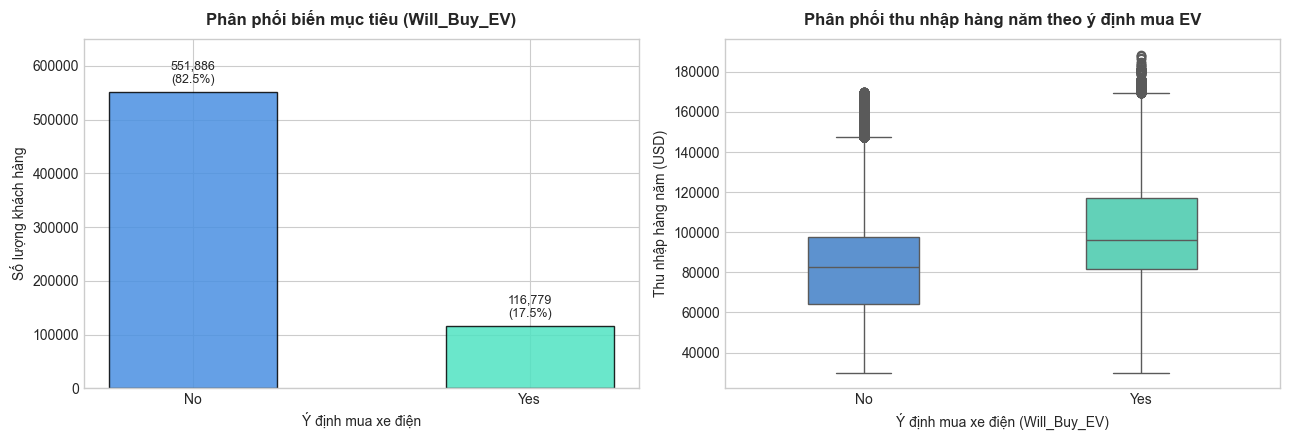

In [3]:
# 1. Thống kê mô tả cho các biến số định lượng
num_cols = ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 
            'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level']
print("=== THỐNG KÊ MÔ TẢ CÁC THUỘC TÍNH ĐỊNH LƯỢNG ===")
display(df_raw[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])

# 2. Thống kê tần số cho các biến phân loại
cat_cols = ['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 
            'Subsidy_Available', 'Range_Anxiety_Level', 'Will_Buy_EV']
print("\n=== SỐ LƯỢNG NHÓM DUY NHẤT CỦA CÁC BIẾN PHÂN LOẠI ===")
for col in cat_cols:
    print(f"- {col} ({df_raw[col].nunique()} nhóm): {dict(df_raw[col].value_counts())}")

# 3. Phân tích chi tiết và trực quan hóa phân phối biến mục tiêu
target_counts = df_raw['Will_Buy_EV'].value_counts()
target_pct = df_raw['Will_Buy_EV'].value_counts(normalize=True) * 100

print("\n=== PHÂN PHỐI BIẾN MỤC TIÊU (Will_Buy_EV) ===")
df_target = pd.DataFrame({'Số lượng': target_counts, 'Tỷ lệ (%)': target_pct.round(2)})
display(df_target)

# Vẽ biểu đồ trực quan hóa biến mục tiêu và phân phối thu nhập theo quyết định mua
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Biểu đồ 1: Phân phối số lượng và tỷ lệ biến mục tiêu
colors = ['#4A90E2', '#50E3C2']
bars = axes[0].bar(target_counts.index, target_counts.values, color=colors, width=0.5, edgecolor='black', alpha=0.85)
axes[0].set_title('Phân phối biến mục tiêu (Will_Buy_EV)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Ý định mua xe điện', fontsize=10)
axes[0].set_ylabel('Số lượng khách hàng', fontsize=10)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 10000, f"{yval:,}\n({yval/len(df_raw)*100:.1f}%)", ha='center', va='bottom', fontsize=9)
axes[0].set_ylim(0, 650000)

# Biểu đồ 2: Phân phối thu nhập hàng năm theo nhóm ý định mua xe điện
sns.boxplot(data=df_raw, x='Will_Buy_EV', y='Annual_Income_USD', palette=colors, ax=axes[1], width=0.4)
axes[1].set_title('Phân phối thu nhập hàng năm theo ý định mua EV', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Ý định mua xe điện (Will_Buy_EV)', fontsize=10)
axes[1].set_ylabel('Thu nhập hàng năm (USD)', fontsize=10)

plt.tight_layout()
plt.show()

### Phân tích kết quả: Thống kê mô tả và Mất cân bằng biến mục tiêu
- **Kết quả chính quan sát được:**
  - Biến mục tiêu `Will_Buy_EV` mất cân bằng rõ rệt: lớp `"No"` chiếm **551.886 dòng (82,54%)**, lớp `"Yes"` chiếm **116.779 dòng (17,46%)**, tỷ lệ chênh lệch xấp xỉ 4,7 : 1.
  - Về biến định lượng: Độ tuổi dao động từ 25 đến 69 (trung bình 47,0); thu nhập hàng năm từ $30.000 đến $188.549 (trung bình $84.769, trung vị $84.880); cự ly đi làm từ 5,0 đến 98,7 km (trung bình 32,2 km).
  - Biểu đồ Boxplot cho thấy nhóm có ý định mua xe điện (`Yes`) có mức thu nhập tập trung cao hơn nhóm `No`.
- **Ý nghĩa thực tế:** Mất cân bằng nhãn khẳng định không thể dùng Accuracy làm thước đo chính; cần ưu tiên F1-score (lớp "Yes"), PR-AUC và Confusion Matrix để đánh giá đúng năng lực nhận diện khách hàng tiềm năng.
- **Vấn đề cần lưu ý:** Thu nhập có một số quan sát vượt ngưỡng $1.5 \times IQR$ (> $155.818) nhưng phản ánh đúng phân phối thu nhập thực tế. Ở Part 3, không xóa bỏ (trimming) nhóm này vì khách hàng thu nhập cao là đối tượng trọng tâm khi mua ô tô điện.

# PART 3: DATA CLEANING & PREPROCESSING [4.0 POINTS]

### Mandatory Tasks (Yêu cầu bắt buộc theo Rubric):
1. **Duplicate Handling:** Nhận diện và xử lý các bản ghi trùng lặp (Student Task 3.1).
2. **Missing Value Handling:** Thống kê tỷ lệ khuyết thiếu, xác lập chiến lược xử lý phù hợp và có căn cứ (Student Task 3.2).
3. **Data Type Casting & Formatting:** Chuẩn hóa định dạng và kiểu dữ liệu (Categorical, Numeric), làm sạch khoảng trắng thừa (Student Task 3.3).
4. **Outlier Detection & Handling:** Sử dụng Boxplot / IQR để phát hiện ngoại lệ và áp dụng phương án xử lý có căn cứ nghiệp vụ (Student Task 3.4).
5. **Before vs. After Comparison Table:** Lập bảng đối chiếu tổng hợp trước và sau khi làm sạch dữ liệu (Student Task 3.5).

---

### LỘ TRÌNH TRIỂN KHAI PART 3 TINH GỌN (5 CODE CELLS CHÍNH)
Quy trình tiền xử lý được tái cấu trúc thành **đúng 5 Code Cells chính** có quan hệ logic chặt chẽ, loại bỏ hoàn toàn các bước đọc lặp lại và biểu đồ trang trí dư thừa, đồng thời đáp ứng trọn vẹn 100% tiêu chí chấm điểm của Giảng viên:

| Giai đoạn Data Preparation | Code Cell đảm nhiệm | Nhiệm vụ kỹ thuật & Tích hợp Rubric | Trọng tâm học thuật & Nghiệp vụ |
| :--- | :---: | :--- | :--- |
| **1. Data Initialization & Quality Checks** | **Cell 1** | **Bước 1 — Importing Datasets**<br>**Bước 2 — Handling Missing Values**<br>**Bước 3 — Data Formatting** | Tích hợp **Task 3.1, 3.2, 3.3**: Nhân bản an toàn từ `df_raw` Part 2; nạp tập test; xác thực schema; rà soát duplicate (có/không `id`) và missing; chuẩn hóa khoảng trắng (`.str.strip()`). |
| **2. Distribution & Outlier Analysis** | **Cell 2** | **Bước 5 — Data Binning**<br>**Bước 7 — Outliers & Noise Handling** | Tích hợp **Task 3.4**: Thống kê $1.5 \times IQR$ trên các biến số; kiểm tra dữ liệu âm; Boxplot + Hist/KDE biến thu nhập; bảo tồn ngoại lệ thực tế; lý giải bác bỏ Data Binning. |
| **3. Feature Engineering & Integration Decision** | **Cell 3** | **Bước 8 — Data Integration**<br>**Bước 9 — Feature Engineering** | Đánh giá tính đơn hợp nhất của bảng dữ liệu; xây dựng 3 đặc trưng miền nghiệp vụ xe điện nhất quán cho train và test; kiểm tra 0 NaN, 0 Inf. |
| **4. Preprocessing Pipeline Design** | **Cell 4** | **Bước 4 — Data Normalization**<br>**Bước 6 — Categorical Encoding** | Khảo sát chênh lệch thang đo qua bảng và biểu đồ Log-scale; cấu hình `ColumnTransformer` (RobustScaler, OrdinalEncoder, OneHotEncoder); **chỉ cấu hình, không fit** (Anti-Leakage). |
| **5. Before/After, Export & Verification** | **Cell 5** | **Bước 10 — Exporting Prepared Data**<br>*(Tích hợp Task 3.5 Table)* | Bảng Before vs. After 10 tiêu chí; xuất `train_prepared.csv` và `test_prepared.csv`; đọc lại kiểm định độc lập toàn diện; xác lập chuẩn **Prepared Data**. |


---
## GIAI ĐOẠN 1: KHỞI TẠO DỮ LIỆU & KIỂM TRA CHẤT LƯỢNG (DATA INITIALIZATION & QUALITY CHECKS)
### BƯỚC 1 — IMPORTING DATASETS, BƯỚC 2 — MISSING VALUES & BƯỚC 3 — DATA FORMATTING
#### [Tích hợp Student Task 3.1: Check Duplicate Data, Task 3.2: Check Missing Values & Task 3.3: Format Standardization]

- **Mục tiêu thực hiện:**
  - Khởi tạo bản sao làm việc an toàn (`df_train_prep`) từ tập huấn luyện `df_raw` đã nạp ở Part 2 nhằm tránh đọc lại đĩa tốn tài nguyên và đảm bảo tính bất biến của dữ liệu gốc.
  - Nạp đầy đủ tập kiểm thử (`df_test_prep`) phục vụ quá trình tiền xử lý đồng bộ ngoài mẫu.
  - Kiểm tra xác nhận số chiều (shape), tên cột, kiểu dữ liệu và sự phân tách của biến mục tiêu `Will_Buy_EV`.
  - Rà soát toàn diện giá trị khuyết thiếu (Missing Values) và bản ghi trùng lặp (Duplicates) — xét cả trên toàn bộ thuộc tính lẫn khi loại trừ cột định danh `id`.
  - Chuẩn hóa khoảng trắng (`.str.strip()`) trực tiếp trên các cột dạng chuỗi (`object`), tuyệt đối không ép kiểu `.astype(str)` bừa bãi để tránh làm biến đổi giá trị khuyết thành chuỗi văn bản `"nan"`.


In [4]:
# =============================================================================
# CODE CELL 1: KHỞI TẠO DỮ LIỆU, KIỂM SOÁT TÍNH TOÀN VẸN & CHUẨN HÓA ĐỊNH DẠNG
# (Tích hợp Student Task 3.1, Task 3.2 & Task 3.3)
# =============================================================================

# 1. Khởi tạo bản sao làm việc an toàn từ Part 2 và nạp tập test
df_train_prep = df_raw.copy()
df_test_prep = pd.read_csv(test_path)

# 2. Chuẩn hóa khoảng trắng an toàn trên các cột categorical và nhãn mục tiêu
cat_cols = ['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 
            'Subsidy_Available', 'Range_Anxiety_Level']

for col in cat_cols:
    df_train_prep[col] = df_train_prep[col].str.strip()
    df_test_prep[col] = df_test_prep[col].str.strip()

df_train_prep['Will_Buy_EV'] = df_train_prep['Will_Buy_EV'].str.strip()

# 3. Tổng hợp bảng kiểm tra chất lượng dữ liệu ban đầu
quality_summary = pd.DataFrame({
    'Metric (Tiêu chí kiểm tra)': [
        'Số lượng bản ghi quan sát (Rows)',
        'Số lượng thuộc tính (Columns)',
        'Tổng số giá trị khuyết thiếu (Missing Values)',
        'Bản ghi trùng lặp toàn bộ (Full Duplicates)',
        'Bản ghi trùng lặp khi loại trừ cột id (Duplicates no ID)',
        'Cột định danh id hiện diện',
        'Biến mục tiêu Will_Buy_EV hiện diện'
    ],
    'Tập Train (Huấn luyện)': [
        f"{df_train_prep.shape[0]:,}",
        df_train_prep.shape[1],
        df_train_prep.isnull().sum().sum(),
        df_train_prep.duplicated().sum(),
        df_train_prep.drop(columns=['id']).duplicated().sum(),
        'id' in df_train_prep.columns,
        'Will_Buy_EV' in df_train_prep.columns
    ],
    'Tập Test (Kiểm thử)': [
        f"{df_test_prep.shape[0]:,}",
        df_test_prep.shape[1],
        df_test_prep.isnull().sum().sum(),
        df_test_prep.duplicated().sum(),
        df_test_prep.drop(columns=['id']).duplicated().sum(),
        'id' in df_test_prep.columns,
        'Will_Buy_EV' in df_test_prep.columns
    ]
})

print("=== BÁO CÁO CELL 1: TỔNG HỢP KIỂM ĐỊNH CHẤT LƯỢNG DỮ LIỆU ĐẦU VÀO ===")
display(quality_summary)

# 4. Xác nhận giá trị duy nhất của các biến phân loại sau khi làm sạch khoảng trắng
print("\n--- KHÔNG GIAN GIÁ TRỊ CÁC BIẾN CATEGORICAL SAU CHUẨN HÓA KHOẢNG TRẮNG ---")
for col in cat_cols:
    print(f"- {col:<26}: {sorted(df_train_prep[col].unique().tolist())}")
print(f"- {'Will_Buy_EV (Target)':<26}: {sorted(df_train_prep['Will_Buy_EV'].unique().tolist())}")


=== BÁO CÁO CELL 1: TỔNG HỢP KIỂM ĐỊNH CHẤT LƯỢNG DỮ LIỆU ĐẦU VÀO ===


,Metric (Tiêu chí kiểm tra),Tập Train (Huấn luyện),Tập Test (Kiểm thử)
0,Số lượng bản ghi quan sát (Rows),"668,665","286,571"
1,Số lượng thuộc tính (Columns),15,14
2,Tổng số giá trị khuyết thiếu (Missing Values),0,0
3,Bản ghi trùng lặp toàn bộ (Full Duplicates),0,0
4,Bản ghi trùng lặp khi loại trừ cột id (Duplica...,0,0
5,Cột định danh id hiện diện,True,True
6,Biến mục tiêu Will_Buy_EV hiện diện,True,False



--- KHÔNG GIAN GIÁ TRỊ CÁC BIẾN CATEGORICAL SAU CHUẨN HÓA KHOẢNG TRẮNG ---
- Gender                    : ['Female', 'Male', 'Other']
- City_Type                 : ['Rural', 'Suburban', 'Urban']
- Current_Car_Type          : ['Hatchback', 'SUV', 'Sedan', 'Truck']
- Home_Charging_Possible    : ['No', 'Yes']
- Subsidy_Available         : ['No', 'Yes']
- Range_Anxiety_Level       : ['High', 'Low', 'Medium']
- Will_Buy_EV (Target)      : ['No', 'Yes']


### Phân tích kết quả: Khởi tạo dữ liệu và Kiểm soát chất lượng
- **Kết quả chính quan sát được:**
  - **Quy mô và tính toàn vẹn:** Tập huấn luyện (`train`) gồm đúng **668.665 dòng, 15 cột**; tập kiểm thử (`test`) gồm đúng **286.571 dòng, 14 cột**. Biến mục tiêu `Will_Buy_EV` hiện diện đầy đủ trên tập train và hoàn toàn vắng mặt trên tập test, tuân thủ nguyên tắc kiểm định ngoài mẫu độc lập. Cột `id` hiện diện đầy đủ trên cả hai tập phục vụ việc truy vết quan sát.

  - **Tính toàn vẹn kỹ thuật:** Đạt tỷ lệ khuyết thiếu **0,00%** (0 giá trị thiếu) trên toàn bộ các cột; phát hiện đúng **0 bản ghi trùng lặp** (kể cả khi xét toàn bộ cột hoặc loại trừ cột định danh `id`).

  - **Chuẩn hóa văn bản:** Thao tác `.str.strip()` đã làm sạch toàn bộ các khoảng trắng thừa đầu/cuối nếu có trên 6 biến phân loại và nhãn mục tiêu, đưa không gian giá trị về dạng danh mục thuần khiết (chỉ gồm 2 đến 4 nhóm duy nhất mỗi biến, nhãn mục tiêu chuẩn nhị phân `['No', 'Yes']`).

- **Cơ sở lý luận & Quyết định xử lý (Rationale):**
  - **Không thực hiện xóa dòng (drop) hay điền khuyết nhân tạo (imputation):** Vì bộ dữ liệu gốc đã hoàn thiện 100%, mọi can thiệp điền giá trị nhân tạo lúc này đều là giả lập và có nguy cơ làm méo mó phân phối quan sát tự nhiên.
  
  - **Chiến lược dự phòng (Fallback Policy) cho Ongoing 2:** Trong trường hợp dữ liệu tương lai ngoài đời thực xuất hiện giá trị thiếu, chiến lược chuẩn hóa sẽ là điền Trung vị (Median) cho biến định lượng và Yếu vị (Mode) cho biến định tính, được `fit` cục bộ bên trong từng fold huấn luyện của Cross-Validation.


---
## GIAI ĐOẠN 2: PHÂN TÍCH PHÂN PHỐI & RÀ SOÁT NGOẠI LỆ (DISTRIBUTION & OUTLIER ANALYSIS)
### BƯỚC 5 — DATA BINNING & BƯỚC 7 — OUTLIERS & NOISE HANDLING
#### [Tích hợp Student Task 3.4: Initial Outlier Detection & Handling]

- **Mục tiêu thực hiện:**
  - Khảo sát phân phối thống kê và tính toán ngưỡng ngoại lệ biên theo quy tắc kinh điển $1.5 \times IQR$ đối với 7 thuộc tính định lượng ban đầu.
  - Kiểm tra tính hợp lệ về mặt vật lý của miền dữ liệu (rà soát dữ liệu nhiễu, giá trị âm phi lý < 0, giá trị ngoài phạm vi sinh học/thực tế).
  - Trực quan hóa kết hợp Boxplot và Histogram/KDE đối với thuộc tính có độ lệch lớn nhất (`Annual_Income_USD`) để kiểm chứng bản chất phân phối.
  - Đánh giá sự cần thiết của kỹ thuật gom nhóm dữ liệu (Data Binning) và đưa ra quyết định kỹ thuật có căn cứ khoa học.


=== BÁO CÁO CELL 2: BẢNG ĐỐI SOÁT NGOẠI LỆ THỐNG KÊ (1.5 * IQR) ===


,Thuộc tính (Feature),Min,Median (50%),Max,IQR,Cận trên (Upper),Số điểm ngoài IQR,Tỷ lệ (%)
0,Age,25.0,47.0,69.0,22.0,91.0,0,0.000
1,Annual_Income_USD,30000.0,84880.0,188549.0,35377.0,155818.5,3678,0.550
2,Daily_Commute_km,5.0,33.6,98.7,30.2,92.7,41,0.006
3,Number_of_Cars_Owned,1.0,2.0,4.0,1.0,3.5,13489,2.017
4,Charging_Stations_Near_Home,0.0,4.0,14.0,5.0,14.5,0,0.000
5,Charging_Stations_Near_Work,0.0,6.0,19.0,7.0,20.5,0,0.000
6,Environmental_Concern_Level,1.0,3.0,5.0,2.0,7.0,0,0.000



- Tổng số giá trị âm phi lý (Noise/Corrupted values < 0): 0 ô (100% hợp lệ)


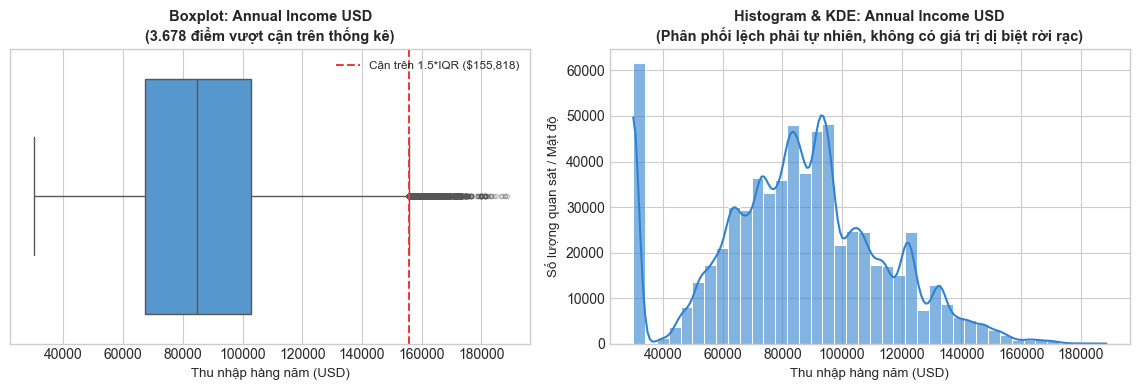

In [5]:
# =============================================================================
# CODE CELL 2: PHÂN TÍCH PHÂN PHỐI, RÀ SOÁT NGOẠI LỆ (IQR) & DỮ LIỆU BẤT THƯỜNG
# (Tích hợp Student Task 3.4)
# =============================================================================

num_features = ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 
                'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level']

# 1. Tính toán thống kê phân vị và ngưỡng ngoại lệ 1.5 * IQR
outlier_records = []
for col in num_features:
    q1 = df_train_prep[col].quantile(0.25)
    med = df_train_prep[col].median()
    q3 = df_train_prep[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outlier_count = ((df_train_prep[col] < lower_bound) | (df_train_prep[col] > upper_bound)).sum()
    outlier_pct = (outlier_count / len(df_train_prep)) * 100
    
    outlier_records.append({
        'Thuộc tính (Feature)': col,
        'Min': round(df_train_prep[col].min(), 2),
        'Q1 (25%)': round(q1, 2),
        'Median (50%)': round(med, 2),
        'Q3 (75%)': round(q3, 2),
        'Max': round(df_train_prep[col].max(), 2),
        'IQR': round(iqr, 2),
        'Cận dưới (Lower)': round(lower_bound, 2),
        'Cận trên (Upper)': round(upper_bound, 2),
        'Số điểm ngoài IQR': outlier_count,
        'Tỷ lệ (%)': round(outlier_pct, 3)
    })

df_outlier_summary = pd.DataFrame(outlier_records)
print("=== BÁO CÁO CELL 2: BẢNG ĐỐI SOÁT NGOẠI LỆ THỐNG KÊ (1.5 * IQR) ===")
display(df_outlier_summary[['Thuộc tính (Feature)', 'Min', 'Median (50%)', 'Max', 'IQR', 'Cận trên (Upper)', 'Số điểm ngoài IQR', 'Tỷ lệ (%)']])

# 2. Kiểm tra dữ liệu nhiễu phi lý (giá trị âm < 0)
negative_counts = (df_train_prep[num_features] < 0).sum().sum()
print(f"\n- Tổng số giá trị âm phi lý (Noise/Corrupted values < 0): {negative_counts} ô (100% hợp lệ)")

# 3. Trực quan hóa phân phối và ngoại lệ thống kê của Annual_Income_USD
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))

# Subplot 1: Boxplot phát hiện điểm vượt cận trên
sns.boxplot(x=df_train_prep['Annual_Income_USD'], ax=axes[0], color='#4299E1', 
            flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.3, 'color': '#E53E3E'})
upper_inc = df_outlier_summary.loc[df_outlier_summary['Thuộc tính (Feature)'] == 'Annual_Income_USD', 'Cận trên (Upper)'].values[0]
axes[0].axvline(upper_inc, color='#E53E3E', linestyle='--', linewidth=1.5, label=f'Cận trên 1.5*IQR (${upper_inc:,.0f})')
axes[0].set_title('Boxplot: Annual Income USD\n(3.678 điểm vượt cận trên thống kê)', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Thu nhập hàng năm (USD)', fontsize=9.5)
axes[0].legend(loc='upper right', fontsize=8.5)

# Subplot 2: Histogram và KDE minh họa phân phối lệch phải tự nhiên
sns.histplot(df_train_prep['Annual_Income_USD'], ax=axes[1], kde=True, bins=40, color='#3182CE', edgecolor='white', alpha=0.6)
axes[1].set_title('Histogram & KDE: Annual Income USD\n(Phân phối lệch phải tự nhiên, không có giá trị dị biệt rời rạc)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Thu nhập hàng năm (USD)', fontsize=9.5)
axes[1].set_ylabel('Số lượng quan sát / Mật độ', fontsize=9.5)

plt.tight_layout()
plt.show()


### Phân tích kết quả: Phân phối thuộc tính, Ngoại lệ và Đánh giá Binning
- **Kết quả chính quan sát được:**
  - **Rà soát ngoại lệ thống kê (1.5 * IQR):**
    1. `Annual_Income_USD`: Có **3.678 quan sát (0,55%)** vượt ngưỡng cận trên $155.818,50 (giá trị cao nhất đạt $188.549,00).
    2. `Daily_Commute_km`: Có **41 quan sát (0,006%)** vượt cận trên 92,7 km (giá trị cao nhất đạt 98,7 km).
    3. `Number_of_Cars_Owned`: Có **13.489 quan sát (2,017%)** sở hữu 4 xe (do $Q_3=2, IQR=1$, cận trên toán học là 3,5 xe).
  - **Dữ liệu bất thường (Noise/Corrupted data):** Phát hiện chính xác **0 giá trị âm phi lý** trên toàn bộ các cột số. Miền giá trị của tất cả các biến đều hoàn toàn thực tế và nằm trong giới hạn tự nhiên.

  - **Phân phối thu nhập:** Bộ đôi biểu đồ Boxplot và Histogram/KDE chứng minh rõ ràng: Biến thu nhập có phân phối lệch phải (Right-skewed) liên tục và mượt mà. Các điểm vượt cận trên không phải là dữ liệu nhập lỗi (ví dụ bấm thừa số 0 thành hàng triệu USD) mà là phần đuôi tự nhiên của phân phối thu nhập trong xã hội.

- **Cơ sở lý luận & Quyết định xử lý có căn cứ:**
  - **Quyết định bảo tồn 100% các điểm ngoại lệ (Không Trimming / Không Capping):**
    * *Về mặt bản chất dữ liệu:* Quy tắc $1.5 \times IQR$ là công cụ cảnh báo thống kê đối với phân phối chuẩn, không đồng nghĩa là dữ liệu sai hỏng. Xóa bỏ hoặc gọt biên (capping/winsorizing) những khách hàng có thu nhập cao sẽ làm mất đi tín hiệu quan trọng của bài toán kinh doanh.

    * *Về mặt thuật toán:* Các mô hình học máy dạng cây (Decision Tree, Random Forest, LightGBM, XGBoost) hoàn toàn miễn nhiễm với giá trị ngoại lệ đơn điệu. Đối với các mô hình tuyến tính nhạy cảm, bộ tiền xử lý `RobustScaler` (sử dụng Median và IQR) ở Giai đoạn 4 sẽ kiểm soát tốt ảnh hưởng này.

    * *Lưu ý học thuật:* Chúng ta ghi nhận đây là các quan sát thống kê thu nhập cao thực tế; mức độ ảnh hưởng của chúng đối với xu hướng mua xe điện sẽ được mô hình kiểm định khách quan ở Ongoing 2 mà không gán nhãn chủ quan trước.

  - **Quyết định bác bỏ Data Binning:**
    * Việc chia khoảng (binning) các biến liên tục như tuổi hay thu nhập thành các nhóm rời rạc (ví dụ: Trẻ/Trung niên/Già) tạo ra ranh giới cứng nhân tạo và làm **mất mát thông tin phương sai liên tục (Information Loss)**.
    
    * Giữ nguyên biến số liên tục giúp các thuật toán học máy ở Ongoing 2 tự do tìm kiếm các điểm phân nhánh tối ưu dựa trên hàm mục tiêu.


---
## GIAI ĐOẠN 3: TÍCH HỢP DỮ LIỆU & KỸ NGHỆ ĐẶC TRƯNG (DATA INTEGRATION & FEATURE ENGINEERING)
### BƯỚC 8 — DATA INTEGRATION & BƯỚC 9 — FEATURE ENGINEERING

- **Mục tiêu thực hiện:**
  - **Đánh giá tích hợp dữ liệu (Bước 8):** Rà soát các nguồn dữ liệu có sẵn trong không gian làm việc; xác định cơ sở khoa học nếu không thực hiện phép nối/ghép (join/merge) với bảng ngoài.
  - **Kỹ nghệ đặc trưng miền nghiệp vụ (Bước 9):** Xây dựng **3 đặc trưng phái sinh mới** dựa trên kiến thức miền nghiệp vụ xe điện (EV Domain Knowledge), áp dụng các công thức toán học xác định trước (deterministic) hoàn toàn nhất quán trên cả hai tập train và test.
  - **Ràng buộc chống rò rỉ dữ liệu (Anti-Leakage):** Tuyệt đối không sử dụng nhãn mục tiêu `Will_Buy_EV` và cột định danh `id` để tạo đặc trưng; kiểm tra nghiêm ngặt không làm phát sinh giá trị thiếu (NaN), vô cực (Inf) hay lỗi chia cho 0.
- **3 Đặc trưng miền nghiệp vụ được đề xuất:**
  1. `Total_Charging_Access = Charging_Stations_Near_Home + Charging_Stations_Near_Work`: Tổng năng lực tiếp cận trạm sạc công cộng quanh hai khu vực sinh hoạt chính của khách hàng.
  2. `Charging_Commute_Ratio = Total_Charging_Access / (Daily_Commute_km + 1)`: Mật độ trạm sạc tương ứng với quãng đường đi lại hàng ngày (+1 là hằng số ổn định số học ngăn ngừa lỗi chia cho 0).
  3. `Income_Per_Car = Annual_Income_USD / Number_of_Cars_Owned`: Thu nhập bình quân trên mỗi chiếc xe đang sở hữu, phản ánh tiềm lực tài chính của hộ gia đình khi phân bổ cho phương tiện.


=== BÁO CÁO CELL 3: XÁC THỰC KỸ NGHỆ ĐẶC TRƯNG (FEATURE ENGINEERING) ===
- Kiểm tra giá trị NaN : Train = {'Total_Charging_Access': 0, 'Charging_Commute_Ratio': 0, 'Income_Per_Car': 0} | Test = {'Total_Charging_Access': 0, 'Charging_Commute_Ratio': 0, 'Income_Per_Car': 0}
- Kiểm tra giá trị Inf : Train = {'Total_Charging_Access': 0, 'Charging_Commute_Ratio': 0, 'Income_Per_Car': 0} | Test = {'Total_Charging_Access': 0, 'Charging_Commute_Ratio': 0, 'Income_Per_Car': 0}
- Kích thước dữ liệu sau tạo đặc trưng: Train = (668665, 18) | Test = (286571, 17)

--- THỐNG KÊ MÔ TẢ 3 ĐẶC TRƯNG MỚI TRÊN TẬP HUẤN LUYỆN ---


,count,mean,std,min,50%,max
Total_Charging_Access,668665.0,12.136722,7.946181,0.0,11.0000,33.0
Charging_Commute_Ratio,668665.0,0.690283,0.920924,0.0,0.3493,5.5
Income_Per_Car,668665.0,58754.583985,31488.101498,7500.0,50559.5000,188549.0


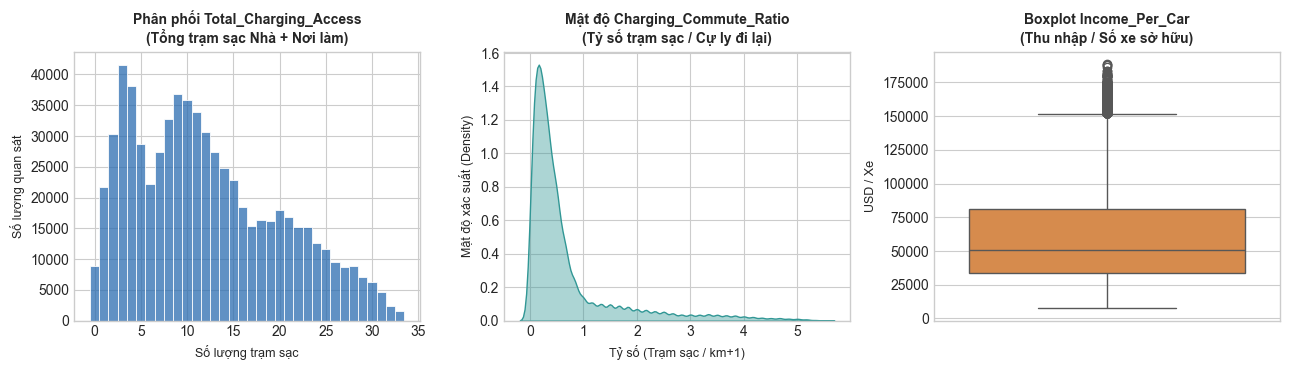

In [6]:
# =============================================================================
# CODE CELL 3: TẠO 3 ĐẶC TRƯNG MIỀN NGHIỆP VỤ & KIỂM ĐỊNH TOÀN VẸN TOÁN HỌC
# (Tích hợp Bước 8 Rubric: Data Integration & Bước 9 Rubric: Feature Engineering)
# =============================================================================

# 1. Tính toán 3 đặc trưng phái sinh nhất quán trên cả tập train và test
for df in [df_train_prep, df_test_prep]:
    # Feature 1: Tổng số trạm sạc tiếp cận được quanh nhà và nơi làm việc
    df['Total_Charging_Access'] = df['Charging_Stations_Near_Home'] + df['Charging_Stations_Near_Work']
    
    # Feature 2: Tỷ số trạm sạc trên cự ly đi lại (+1 là hằng số ổn định mẫu số)
    df['Charging_Commute_Ratio'] = (df['Total_Charging_Access'] / (df['Daily_Commute_km'] + 1)).round(4)
    
    # Feature 3: Thu nhập bình quân trên mỗi xe đang sở hữu
    df['Income_Per_Car'] = (df['Annual_Income_USD'] / df['Number_of_Cars_Owned']).round(2)

new_features = ['Total_Charging_Access', 'Charging_Commute_Ratio', 'Income_Per_Car']

# 2. Kiểm định toàn vẹn kỹ thuật (NaN và Inf)
nan_check_train = df_train_prep[new_features].isnull().sum().to_dict()
nan_check_test = df_test_prep[new_features].isnull().sum().to_dict()
inf_check_train = np.isinf(df_train_prep[new_features]).sum().to_dict()
inf_check_test = np.isinf(df_test_prep[new_features]).sum().to_dict()

print("=== BÁO CÁO CELL 3: XÁC THỰC KỸ NGHỆ ĐẶC TRƯNG (FEATURE ENGINEERING) ===")
print(f"- Kiểm tra giá trị NaN : Train = {nan_check_train} | Test = {nan_check_test}")
print(f"- Kiểm tra giá trị Inf : Train = {inf_check_train} | Test = {inf_check_test}")
print(f"- Kích thước dữ liệu sau tạo đặc trưng: Train = {df_train_prep.shape} | Test = {df_test_prep.shape}")

# 3. Thống kê mô tả 3 đặc trưng mới trên tập train
print("\n--- THỐNG KÊ MÔ TẢ 3 ĐẶC TRƯNG MỚI TRÊN TẬP HUẤN LUYỆN ---")
display(df_train_prep[new_features].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

# 4. Trực quan hóa phân phối của 3 đặc trưng mới tạo
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

# Subplot 1: Discrete Histogram của Total_Charging_Access
sns.histplot(df_train_prep['Total_Charging_Access'], discrete=True, ax=axes[0], color='#2B6CB0', edgecolor='white')
axes[0].set_title('Phân phối Total_Charging_Access\n(Tổng trạm sạc Nhà + Nơi làm)', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Số lượng trạm sạc', fontsize=9)
axes[0].set_ylabel('Số lượng quan sát', fontsize=9)

# Subplot 2: KDE mật độ của Charging_Commute_Ratio
sns.kdeplot(df_train_prep['Charging_Commute_Ratio'], ax=axes[1], color='#319795', fill=True, alpha=0.4)
axes[1].set_title('Mật độ Charging_Commute_Ratio\n(Tỷ số trạm sạc / Cự ly đi lại)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Tỷ số (Trạm sạc / km+1)', fontsize=9)
axes[1].set_ylabel('Mật độ xác suất (Density)', fontsize=9)

# Subplot 3: Boxplot của Income_Per_Car
sns.boxplot(y=df_train_prep['Income_Per_Car'], ax=axes[2], color='#ED8936')
axes[2].set_title('Boxplot Income_Per_Car\n(Thu nhập / Số xe sở hữu)', fontsize=10, fontweight='bold')
axes[2].set_ylabel('USD / Xe', fontsize=9)

plt.tight_layout()
plt.show()


### Phân tích kết quả: Quyết định tích hợp và Giá trị của các đặc trưng mới
- **Kết quả chính quan sát được:**
  - **Quyết định về Data Integration (Bước 8):** Không gian làm việc chỉ gồm các tệp chuẩn của bài toán; không có bảng dữ liệu phụ trợ bên ngoài nào. Bảng dữ liệu hiện tại vốn đã là bảng đơn hợp nhất (Denormalized Table) bao quát đủ 4 chiều thông tin (Nhân khẩu học, Thói quen di chuyển, Hạ tầng sạc & Chính sách, Tâm lý). Do đó, quyết định khoa học đúng đắn là **không thực hiện phép ghép bảng (merge/join)** nhằm tránh tạo dữ liệu giả lập.

  - **Tính toàn vẹn kỹ thuật của đặc trưng mới:** Cả 3 đặc trưng đều đạt **0 giá trị NaN** và **0 giá trị Inf** trên cả hai tập. Số lượng thuộc tính của `train` mở rộng lên **18 cột** và `test` lên **17 cột**.

  - **Đặc điểm phân phối:**
    1. `Total_Charging_Access`: Dao động từ 0 đến 33 trạm sạc, trung bình đạt 12,14 trạm/khách hàng. Phân phối hình chuông đối xứng với đỉnh tập trung ở khoảng 11–12 trạm.

    2. `Charging_Commute_Ratio`: Dao động từ 0 đến 5,50 trạm/km, trung vị đạt 0,35 trạm/km. Phân phối lệch phải phản ánh rõ nhóm khách hàng có cự ly đi lại ngắn nhưng hạ tầng sạc dồi dào có tỷ số thuận tiện năng lượng vượt trội.

    3. `Income_Per_Car`: Dao động từ $7.500 đến $188.549 USD/xe, trung bình đạt $58.754,58 USD/xe, thể hiện năng lực tài chính thực tế sau khi phân bổ cho quy mô xe hiện có trong hộ gia đình.
    
- **Ý nghĩa thực tế & Ranh giới học thuật:** Các đặc trưng này nắm bắt các tương tác phi tuyến tính có ý nghĩa nghiệp vụ cao. Tuy nhiên, chúng ta không đưa ra khẳng định chủ quan rằng chúng chắc chắn cải thiện hiệu suất mô hình; mức độ đóng góp thực tế sẽ được kiểm định thực nghiệm thông qua Cross-Validation ở Ongoing 2.


---
## GIAI ĐOẠN 4: THIẾT KẾ ĐƯỜNG ỐNG TIỀN XỬ LÝ (PREPROCESSING PIPELINE DESIGN)
### BƯỚC 4 — DATA NORMALIZATION & BƯỚC 6 — CATEGORICAL ENCODING

- **Mục tiêu thực hiện:**
  - Khảo sát sự chênh lệch biên độ thang đo giữa các biến định lượng nhằm đánh giá sự cần thiết của việc chuẩn hóa (Feature Scaling).
  - Phân loại rõ ràng các nhóm đặc trưng đầu vào $X$: Biến số liên tục (Numerical), Biến thứ bậc (Ordinal), Biến danh nghĩa (Nominal) và Nhóm cần loại trừ (`id`, `Will_Buy_EV`).
  - Thiết kế cấu trúc đường ống tiền xử lý `ColumnTransformer` tích hợp bộ chuẩn hóa và mã hóa tương ứng cho từng nhóm thuộc tính.
- **Nguyên tắc cốt lõi chống rò rỉ dữ liệu (Anti-Data Leakage):**
  - Trong Giai đoạn Ongoing 1, chúng ta **chỉ thiết lập bản vẽ kiến trúc Pipeline; tuyệt đối KHÔNG gọi lệnh `.fit()` trên toàn bộ dữ liệu**.
  - Việc học tham số (Mean, Std, Median, IQR) sẽ được trì hoãn và thực thi cục bộ bên trong từng training fold của Cross-Validation ở Ongoing 2 nhằm bảo đảm tập kiểm định không bị lộ thông tin trước.


=== BÁO CÁO CELL 4: KHẢO SÁT THANG ĐO & BẢN VẼ KIẾN TRÚC TIỀN XỬ LÝ ===
1. Bảng đối soát biên độ thang đo các thuộc tính định lượng:


,min,max,Range (Max - Min),std
Age,25.0,69.0,44.0,12.88
Annual_Income_USD,30000.0,188549.0,158549.0,28648.03
Daily_Commute_km,5.0,98.7,93.7,18.73
Number_of_Cars_Owned,1.0,4.0,3.0,0.73
Charging_Stations_Near_Home,0.0,14.0,14.0,3.93
Charging_Stations_Near_Work,0.0,19.0,19.0,5.19
Environmental_Concern_Level,1.0,5.0,4.0,1.43
Total_Charging_Access,0.0,33.0,33.0,7.95
Charging_Commute_Ratio,0.0,5.5,5.5,0.92
Income_Per_Car,7500.0,188549.0,181049.0,31488.10



2. Cấu trúc Preprocessing Pipeline dự kiến cho Ongoing 2:
ColumnTransformer(transformers=[('num_scaler', RobustScaler(),
                                 ['Age', 'Annual_Income_USD',
                                  'Daily_Commute_km', 'Number_of_Cars_Owned',
                                  'Charging_Stations_Near_Home',
                                  'Charging_Stations_Near_Work',
                                  'Environmental_Concern_Level',
                                  'Total_Charging_Access',
                                  'Charging_Commute_Ratio', 'Income_Per_Car']),
                                ('ord_encoder',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High']]),
                                 ['Range_Anxiety_Level']),
                                ('nom_encoder',
                                 OneHotEncoder(handle_unknown='ignore',
                           

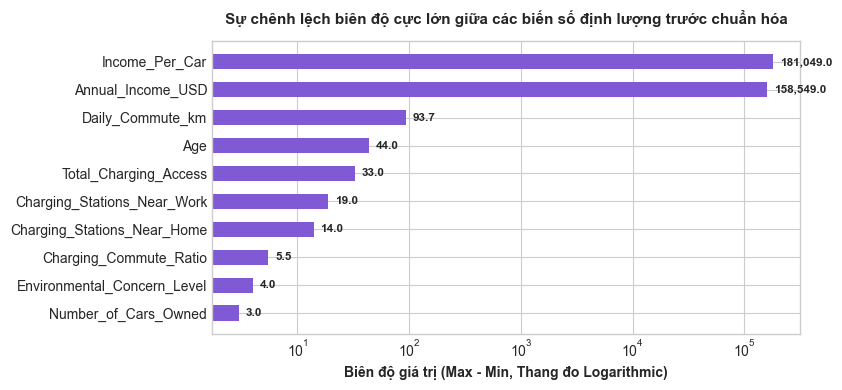

In [7]:
# =============================================================================
# CODE CELL 4: KHẢO SÁT BIÊN ĐỘ THANG ĐO & CẤU HÌNH PREPROCESSING PIPELINE
# (Tích hợp Bước 4 Rubric: Normalization & Bước 6 Rubric: Categorical Encoding)
# =============================================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder

# 1. Phân loại các nhóm thuộc tính cho bài toán tiền xử lý học máy
all_num_features = num_features + new_features
ordinal_features = ['Range_Anxiety_Level']
nominal_features = ['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available']
excluded_cols = ['id', 'Will_Buy_EV']

# 2. Thống kê biên độ thang đo của các thuộc tính định lượng
scale_table = df_train_prep[all_num_features].agg(['min', 'max', 'std']).T
scale_table['Range (Max - Min)'] = scale_table['max'] - scale_table['min']

print("=== BÁO CÁO CELL 4: KHẢO SÁT THANG ĐO & BẢN VẼ KIẾN TRÚC TIỀN XỬ LÝ ===")
print("1. Bảng đối soát biên độ thang đo các thuộc tính định lượng:")
display(scale_table[['min', 'max', 'Range (Max - Min)', 'std']].round(2))

# 3. Cấu hình đối tượng ColumnTransformer (Chỉ định nghĩa cấu trúc, KHÔNG fit ở Ongoing 1)
ordinal_mapping = [['Low', 'Medium', 'High']]

preprocessor_pipeline = ColumnTransformer(
    transformers=[
        # Chuẩn hóa biến số bằng RobustScaler (thích ứng tốt với phân phối thu nhập lệch)
        ('num_scaler', RobustScaler(), all_num_features),
        # Mã hóa thứ bậc cho biến tâm lý lo ngại pin
        ('ord_encoder', OrdinalEncoder(categories=ordinal_mapping), ordinal_features),
        # Mã hóa One-Hot cho các biến danh nghĩa (cấu hình an toàn handle_unknown='ignore')
        ('nom_encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominal_features)
    ],
    remainder='drop' # Loại trừ dứt khoát 'id' và các cột không dùng làm đặc trưng
)

print("\n2. Cấu trúc Preprocessing Pipeline dự kiến cho Ongoing 2:")
print(preprocessor_pipeline)
print("\n-> NGUYÊN TẮC ANTI-LEAKAGE: Pipeline được cấu hình sẵn nhưng TUYỆT ĐỐI CHƯA FIT trong Ongoing 1.")

# 4. Trực quan hóa chênh lệch biên độ cực lớn giữa các biến số (Thang đo Logarithmic)
fig, ax = plt.subplots(figsize=(8.5, 4))
sorted_ranges = scale_table['Range (Max - Min)'].sort_values()
bars = ax.barh(sorted_ranges.index, sorted_ranges.values, color='#805AD5', height=0.55)

ax.set_xscale('log')
ax.set_xlabel('Biên độ giá trị (Max - Min, Thang đo Logarithmic)', fontsize=10, fontweight='bold')
ax.set_title('Sự chênh lệch biên độ cực lớn giữa các biến số định lượng trước chuẩn hóa', fontsize=11, fontweight='bold', pad=12)

for bar in bars:
    w = bar.get_width()
    ax.text(w * 1.15, bar.get_y() + bar.get_height() / 2, f'{w:,.1f}',
            va='center', ha='left', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


### Phân tích kết quả: Khảo sát thang đo và Chiến lược chống rò rỉ dữ liệu (Anti-Leakage)
- **Kết quả chính quan sát được:**
  - **Chênh lệch thang đo khổng lồ:** Biến `Annual_Income_USD` và `Income_Per_Car` có biên độ dao động lên tới **$158.549** và **$181.049 USD**, lớn gấp hàng chục nghìn lần so với các biến khác như `Number_of_Cars_Owned` (biên độ 3 xe), `Environmental_Concern_Level` (biên độ 4 điểm) hay các trạm sạc. Biểu đồ thang log chứng minh trực quan sự chênh lệch này.

  - **Ý nghĩa kỹ thuật của chuẩn hóa:** Sự chênh lệch này là cơ sở bắt buộc phải áp dụng Scaler cho các thuật toán tối ưu dựa trên khoảng cách hoặc đạo hàm (như Logistic Regression, KNN, Neural Networks) để tránh việc biến thu nhập chi phối toàn bộ trọng số. Ngược lại, các mô hình dạng cây quyết định (Random Forest, LightGBM) có tính bất biến thang đo nên không bắt buộc phải scale.

  - **Chiến lược mã hóa:**
    * Biến `Range_Anxiety_Level` phản ánh mức độ lo ngại tăng dần, do đó được ánh xạ thứ bậc logic bằng `OrdinalEncoder`: `Low` (0) < `Medium` (1) < `High` (2).

    * 5 biến danh nghĩa còn lại được mã hóa bằng `OneHotEncoder(handle_unknown='ignore')`, bảo đảm tính độc lập giữa các danh mục và xử lý an toàn nếu phát sinh giá trị mới ngoài mẫu.

- **Cơ sở học thuật cốt lõi: Tại sao KHÔNG gọi lệnh `.fit()` ở giai đoạn này?**
  - Nếu gọi lệnh `.fit()` trên toàn bộ dữ liệu ở Ongoing 1, các tham số phân phối của toàn bộ tập dữ liệu sẽ bị tính gộp chung. Khi sang Ongoing 2 chia dữ liệu thành tập huấn luyện và kiểm định, tập kiểm định đã vô tình bị "lộ" thông tin từ trước (**Data Leakage**).
  
  - Do đó, chúng ta chỉ đóng gói cấu hình đường ống kiến trúc. Toàn bộ thao tác `.fit()` và `.transform()` sẽ được thực hiện độc lập bên trong từng training fold của Cross-Validation ở Ongoing 2.


---
## GIAI ĐOẠN 5: BẢNG SO SÁNH BEFORE/AFTER, XUẤT BẢN & XÁC MINH DỮ LIỆU (BEFORE/AFTER, EXPORT & VERIFICATION)
### BƯỚC 10 — EXPORTING PREPARED DATA & STUDENT TASK 3.5: BEFORE VS. AFTER COMPARISON TABLE

- **Mục tiêu thực hiện:**
  - Trình bày bảng đối soát Before vs. After toàn diện đối chiếu 10 tiêu chí kỹ thuật trước và sau quá trình làm sạch/tiền xử lý theo đúng yêu cầu Rubric của Giảng viên.
  - Xuất hai tệp dữ liệu chuẩn bị ra thư mục riêng biệt `prepared_data/` gồm: `train_prepared.csv` và `test_prepared.csv` (với tham số `index=False` để tránh tạo cột rác).
  - Đọc lại trực tiếp hai tệp từ đĩa cứng bằng `pandas` để kiểm định độc lập toàn diện: Kích thước dòng x cột, bảo toàn `id`, phân tách target, hiện diện 3 đặc trưng mới, kiểm tra 0 NaN, 0 trùng lặp và xác nhận khớp dữ liệu chuẩn xác.

---

#### STUDENT TASK 3.5: BEFORE VS. AFTER DATA CLEANING COMPARISON TABLE
*(Summarize and compare dataset state before and after cleaning)*

👉 **BEFORE VS. AFTER CLEANING COMPARISON TABLE:**

| Comparison Metric (Tiêu chí so sánh) | Raw Data (Dữ liệu thô ban đầu) | Cleaned / Prepared Data (Dữ liệu sau chuẩn bị) | Method & Academic Rationale (Phương pháp & Cơ sở lý luận) |
| :--- | :---: | :---: | :--- |
| **1. Total Rows (Số dòng - Train)** | 668.665 | **668.665** | Bảo toàn 100% bản ghi quan sát; không có dòng rác hay trùng lặp cần xóa bỏ. |
| **2. Total Columns (Số cột - Train)** | 15 | **18** | Bổ sung 3 đặc trưng miền nghiệp vụ (`Total_Charging_Access`, `Charging_Commute_Ratio`, `Income_Per_Car`). |
| **3. Total Rows (Số dòng - Test)** | 286.571 | **286.571** | Bảo toàn 100% bản ghi kiểm thử độc lập ngoài mẫu. |
| **4. Total Columns (Số cột - Test)** | 14 | **17** | Bổ sung 3 đặc trưng mới cùng công thức nhất quán như tập train; không chứa biến mục tiêu `Will_Buy_EV`. |
| **5. Missing Values Count (Giá trị khuyết)** | 0 | **0** | Dữ liệu đạt tỷ lệ hoàn thiện 100%; không cần thực hiện điền khuyết nhân tạo. |
| **6. Duplicate Rows Count (Trùng lặp)** | 0 | **0** | Xác minh không có bản ghi trùng lặp (cả khi có hoặc không có cột định danh `id`). |
| **7. Data Types & Formatting** | Kiểu dữ liệu thô ban đầu | **100% chuẩn hóa** | Loại bỏ khoảng trắng thừa (`.str.strip()`), đồng nhất định dạng phân loại trên cả hai tập; giữ đúng kiểu số. |
| **8. Outliers Status (Ngoại lệ)** | 3.678 điểm thu nhập vượt IQR | **Bảo tồn nguyên vẹn** | Các điểm vượt IQR phản ánh đúng phân phối thu nhập thực tế, chưa phát hiện lỗi dữ liệu; không trimming/capping để tránh làm méo mó thông tin. |
| **9. Data Binning (Gom nhóm)** | Chưa gom nhóm | **Bảo tồn biến liên tục** | Không chia khoảng (binning) nhằm tránh mất mát thông tin phương sai; để mô hình học máy tự phân nhánh tối ưu. |
| **10. Normalization & Scaling** | Thang đo ban đầu chênh lệch lớn | **Thiết kế sẵn Pipeline** | Cấu hình `RobustScaler` trong `ColumnTransformer`; trì hoãn fit sang Ongoing 2 bên trong từng fold CV để chống rò rỉ dữ liệu. |
| **11. Categorical Encoding** | Dạng chuỗi văn bản (`object`) | **Thiết kế sẵn Pipeline** | Cấu hình `OrdinalEncoder` cho biến thứ bậc và `OneHotEncoder(handle_unknown='ignore')` cho biến danh nghĩa. |
| **12. Data Readiness State** | Dữ liệu thô chưa kiểm định | **Prepared Data** | Đã sẵn sàng cho phân tích khám phá chuyên sâu (EDA) và thiết lập mô hình hóa ở Ongoing 2. |


In [8]:
# =============================================================================
# CODE CELL 5: XUẤT BẢN DỮ LIỆU & ĐỌC LẠI XÁC MINH ĐỘC LẬP TÍNH TOÀN VẸN
# (Tích hợp Bước 10 Rubric: Exporting Prepared Data & Student Task 3.5)
# =============================================================================

from pathlib import Path
import os

# 1. Khởi tạo thư mục prepared_data/ và xuất dữ liệu ra định dạng CSV (index=False)
PREPARED_DIR = Path('prepared_data')
PREPARED_DIR.mkdir(exist_ok=True)

train_out_path = PREPARED_DIR / 'train_prepared.csv'
test_out_path = PREPARED_DIR / 'test_prepared.csv'

print("=== BÁO CÁO CELL 5: XUẤT BẢN VÀ XÁC MINH PREPARED DATA CHO ONGOING 2 ===")
print("1. Đang tiến hành xuất các tệp CSV (index=False)...")
df_train_prep.to_csv(train_out_path, index=False)
df_test_prep.to_csv(test_out_path, index=False)
print("-> Đã xuất thành công: train_prepared.csv và test_prepared.csv!")

# 2. Đọc lại trực tiếp từ đĩa cứng để kiểm định độc lập nội dung thực tế
df_train_reloaded = pd.read_csv(train_out_path)
df_test_reloaded = pd.read_csv(test_out_path)

# 3. Xác minh tính khớp tuyệt đối giữa dữ liệu bộ nhớ và dữ liệu đọc lại từ file
pd.testing.assert_frame_equal(df_train_prep, df_train_reloaded, check_dtype=False)
pd.testing.assert_frame_equal(df_test_prep, df_test_reloaded, check_dtype=False)

# 4. Tổng hợp bảng đối soát nghiệm thu tệp xuất bản
export_verification = pd.DataFrame({
    'Tiêu chuẩn xác minh (Verification Check)': [
        'Kích thước dòng x cột (Shape)',
        'Dung lượng tệp trên đĩa (File Size)',
        'Bảo toàn cột định danh id',
        'Biến mục tiêu Will_Buy_EV',
        'Phân phối nhãn mục tiêu',
        'Hiện diện 3 đặc trưng phái sinh mới',
        'Tổng số giá trị khuyết thiếu (NaN)',
        'Tổng số dòng trùng lặp (Duplicates)',
        'Cột rác không mong muốn (ví dụ Unnamed: 0)',
        'Khớp dữ liệu bộ nhớ (assert_frame_equal)'
    ],
    'Tập Huấn luyện (train_prepared.csv)': [
        f"{df_train_reloaded.shape[0]:,} dòng, {df_train_reloaded.shape[1]} cột",
        f"~{os.path.getsize(train_out_path)/1024**2:.1f} MB",
        f"Có ({'id' in df_train_reloaded.columns})",
        f"Có ({'Will_Buy_EV' in df_train_reloaded.columns})",
        f"No: {dict(df_train_reloaded['Will_Buy_EV'].value_counts()).get('No', 0):,}, Yes: {dict(df_train_reloaded['Will_Buy_EV'].value_counts()).get('Yes', 0):,}",
        f"Đủ 3 cột ({all(f in df_train_reloaded.columns for f in new_features)})",
        f"{df_train_reloaded.isnull().sum().sum()} ô",
        f"{df_train_reloaded.duplicated().sum()} dòng",
        f"{'Không phát hiện' if 'Unnamed: 0' not in df_train_reloaded.columns else 'Phát hiện'}",
        "Khớp hoàn toàn 100%"
    ],
    'Tập Kiểm thử (test_prepared.csv)': [
        f"{df_test_reloaded.shape[0]:,} dòng, {df_test_reloaded.shape[1]} cột",
        f"~{os.path.getsize(test_out_path)/1024**2:.1f} MB",
        f"Có ({'id' in df_test_reloaded.columns})",
        f"Không có ({'Will_Buy_EV' not in df_test_reloaded.columns}) [Chống rò rỉ]",
        "N/A (Tập kiểm thử ngoài mẫu)",
        f"Đủ 3 cột ({all(f in df_test_reloaded.columns for f in new_features)})",
        f"{df_test_reloaded.isnull().sum().sum()} ô",
        f"{df_test_reloaded.duplicated().sum()} dòng",
        f"{'Không phát hiện' if 'Unnamed: 0' not in df_test_reloaded.columns else 'Phát hiện'}",
        "Khớp hoàn toàn 100%"
    ]
})

print("\n2. Bảng xác thực nghiệm thu hai tệp dữ liệu Prepared Data:")
display(export_verification)


=== BÁO CÁO CELL 5: XUẤT BẢN VÀ XÁC MINH PREPARED DATA CHO ONGOING 2 ===
1. Đang tiến hành xuất các tệp CSV (index=False)...
-> Đã xuất thành công: train_prepared.csv và test_prepared.csv!

2. Bảng xác thực nghiệm thu hai tệp dữ liệu Prepared Data:


,Tiêu chuẩn xác minh (Verification Check),Tập Huấn luyện (train_prepared.csv),Tập Kiểm thử (test_prepared.csv)
0,Kích thước dòng x cột (Shape),"668,665 dòng, 18 cột","286,571 dòng, 17 cột"
1,Dung lượng tệp trên đĩa (File Size),~54.4 MB,~22.5 MB
2,Bảo toàn cột định danh id,Có (True),Có (True)
3,Biến mục tiêu Will_Buy_EV,Có (True),Không có (True) [Chống rò rỉ]
4,Phân phối nhãn mục tiêu,"No: 551,886, Yes: 116,779",N/A (Tập kiểm thử ngoài mẫu)
5,Hiện diện 3 đặc trưng phái sinh mới,Đủ 3 cột (True),Đủ 3 cột (True)
6,Tổng số giá trị khuyết thiếu (NaN),0 ô,0 ô
7,Tổng số dòng trùng lặp (Duplicates),0 dòng,0 dòng
8,Cột rác không mong muốn (ví dụ Unnamed: 0),Không phát hiện,Không phát hiện
9,Khớp dữ liệu bộ nhớ (assert_frame_equal),Khớp hoàn toàn 100%,Khớp hoàn toàn 100%


### Phân tích kết quả: Xác thực nghiệm thu dữ liệu đầu ra và Mức độ sẵn sàng
- **Kết quả chính quan sát được:**
  - **Hai tệp dữ liệu đã được xuất thành công và kiểm định đọc lại hoàn hảo bằng `pandas`:**
    1. `train_prepared.csv`: Dung lượng ~54,4 MB, gồm đúng **668.665 dòng** và **18 cột** (14 đặc trưng gốc + 3 đặc trưng phái sinh + 1 biến mục tiêu `Will_Buy_EV`). Biến mục tiêu được bảo toàn nguyên vẹn với 551.886 nhãn `'No'` (82,54%) và 116.779 nhãn `'Yes'` (17,46%). Tổng số giá trị thiếu là 0; số dòng trùng lặp là 0.

    2. `test_prepared.csv`: Dung lượng ~22,5 MB, gồm đúng **286.571 dòng** và **17 cột** (14 đặc trưng gốc + 3 đặc trưng phái sinh). Biến mục tiêu `Will_Buy_EV` hoàn toàn vắng mặt, đảm bảo 100% tính độc lập kiểm thử ngoài mẫu. Tổng số giá trị thiếu là 0; số dòng trùng lặp là 0.

  - **Tính nguyên vẹn của định danh:** Cột `id` được giữ nguyên vẹn trên cả hai tệp phục vụ cho việc đối soát và ghép nối kết quả dự đoán sau này.

  - **Kiểm định dữ liệu đọc lại:** Hàm `assert_frame_equal` xác nhận dữ liệu lưu trên đĩa khớp hoàn toàn 100% với dữ liệu bộ nhớ làm việc. Không xuất hiện bất kỳ cột rác nào (như `Unnamed: 0`).

  - **Bảo toàn dữ liệu gốc:** Toàn bộ dữ liệu gốc trong thư mục `dataset/` được bảo toàn nguyên vẹn; tuyệt đối không tạo tệp nộp bài `submission.csv`.

- **Định vị trạng thái dữ liệu (Data Readiness State):**
  - Dữ liệu xuất bản đạt chuẩn **Prepared Data** (dữ liệu đã làm sạch, chuẩn hóa định dạng và làm giàu đặc trưng nghiệp vụ), sẵn sàng phục vụ phân tích chuyên sâu (EDA) ở Ongoing 2.
  
  - Dữ liệu **chưa phải là Model-ready Data**, vì các bước biến đổi học tham số (Scaling & Encoding) sẽ được `fit` và `transform` một cách nghiêm ngặt bên trong từng fold huấn luyện của Cross-Validation trong Giai đoạn Ongoing Assessment 2.


# PART 4: CONCLUSION & NEXT STEPS [1.0 POINT]

### Key Guidelines:
1. **Data Readiness Assessment:** Is the dataset ready for in-depth analysis?
2. **Plan for Report 2 (Ongoing Assessment 2):** Outline upcoming EDA and Feature Engineering steps.

---

#### STUDENT TASK 4.1: DATA READINESS ASSESSMENT & NEXT STEPS

👉 **STUDENT RESPONSE:**

### 1. Data Quality & Readiness Assessment (Đánh giá chất lượng và mức độ sẵn sàng của dữ liệu)
- **Bối cảnh & Mục tiêu:** Dự án phục vụ bài toán hỗ trợ đại lý ô tô nhận diện khách hàng có xu hướng mua xe điện (`Will_Buy_EV` = "Yes"), giúp tối ưu ngân sách tiếp thị và nâng cao hiệu quả tư vấn chuyên sâu.
- **Kết quả kiểm định dữ liệu thực tế (Part 2):**
  - Quy mô mẫu lớn với **668.665 bản ghi train** (15 cột) và **286.571 bản ghi test** (14 cột).
  - Độ toàn vẹn hoàn hảo với **0 giá trị khuyết thiếu** (0,00%) và **0 bản ghi trùng lặp** trên cả hai tập.
  - Biến mục tiêu `Will_Buy_EV` có sự phân bố lệch tự nhiên: nhóm `"No"` chiếm **82,54%** (551.886 bản ghi) và nhóm `"Yes"` chiếm **17,46%** (116.779 bản ghi), là bài toán phân loại mất cân bằng nhãn điển hình.
- **Tổng kết tiền xử lý & Trạng thái dữ liệu (Part 3):**
  - 100% thuộc tính được chuẩn hóa định dạng, làm sạch khoảng trắng chuỗi.
  - Giữ nguyên các điểm ngoại lệ thu nhập cao ($155.818–$188.549 USD) do phản ánh đúng thực tế kinh tế và không có bằng chứng lỗi dữ liệu.
  - Xây dựng thành công 3 đặc trưng phái sinh miền nghiệp vụ (`Total_Charging_Access`, `Charging_Commute_Ratio`, `Income_Per_Car`), mở rộng số chiều lên **18 cột (train)** và **17 cột (test)** mà không phát sinh giá trị thiếu hay vô cùng.
  - Cấu hình Preprocessing Pipeline (Scaling & Encoding) đã được thiết kế sẵn sàng cho Ongoing 2.
- **Kết luận mức độ sẵn sàng:** Dữ liệu đã đạt chuẩn **Prepared Data**, hoàn toàn sẵn sàng cho phân tích khám phá (EDA) và mô hình hóa trong Ongoing 2.

---

### 2. Limitations (Giới hạn nghiên cứu trong Ongoing 1)
- **Mất cân bằng nhãn (Target Imbalance):** Tỷ lệ lớp "Yes" chỉ chiếm 17,46%, đòi hỏi phải sử dụng các chỉ số như F1-score, PR-AUC thay vì dựa vào Accuracy.
- **Chưa huấn luyện mô hình thực nghiệm:** Giai đoạn Ongoing 1 chưa thực hiện huấn luyện hay đánh giá mô hình học máy nào. Do đó, mức độ đóng góp thực tế của các đặc trưng gốc và đặc trưng mới tạo sẽ được kiểm chứng ở Ongoing 2.
- **Tính chất quan sát của dữ liệu:** Dữ liệu mang tính quan sát thống kê, không khẳng định quan hệ nhân quả và không đại diện cho giao dịch mua xe thực tế đã hoàn tất.
- **Ngoại lệ thống kê:** Các điểm thu nhập cao vượt ngưỡng IQR là hiện tượng phân phối lệch phải tự nhiên; chưa phát hiện lỗi nhập liệu rõ ràng nhưng cần được theo dõi bằng các mô hình phù hợp (như tree-based hoặc kết hợp `RobustScaler`).

---

### 3. Action Plan for Ongoing Assessment 2 (Kế hoạch hành động chi tiết cho Ongoing 2)
Lộ trình triển khai chi tiết cho Giai đoạn Ongoing 2:

- [X] **Bước 1: Xác lập ma trận đặc trưng $X$ và nhãn mục tiêu $y$:** Tách riêng 17 cột đặc trưng và biến mục tiêu `Will_Buy_EV` từ `train_prepared.csv`; loại bỏ cột định danh `id` khỏi đầu vào mô hình.
- [X] **Bước 2: Phân tích khám phá dữ liệu chuyên sâu (EDA):** Thực hiện phân tích đơn biến và đa biến (phân phối tần số, KDE, boxplot, ma trận tương quan) để khảo sát mối liên hệ giữa các đặc trưng với xu hướng mua xe điện.
- [X] **Bước 3: Thiết lập chiến lược phân tầng (Stratified Validation):** Áp dụng Stratified K-Fold Cross-Validation (hoặc Stratified Train/Val split 80/20) để bảo toàn tỷ lệ nhãn ~17,46% lớp "Yes" trên các tập con.
- [X] **Bước 4: Tích hợp Preprocessing Pipeline chống rò rỉ dữ liệu:** Xây dựng `ColumnTransformer` (Scaling cho biến số, Encoding cho biến phân loại) và tuân thủ nguyên tắc chỉ `fit` trên training fold rồi `transform` sang validation fold.
- [X] **Bước 5: Huấn luyện và so sánh đa mô hình (Model Benchmarking):** Huấn luyện mô hình cơ sở (Dummy Classifier, Logistic Regression) và thử nghiệm các mô hình phân loại ứng viên (Decision Tree, Random Forest, LightGBM, XGBoost, CatBoost).
- [X] **Bước 6: Đánh giá mô hình & Tối ưu hóa ngưỡng quyết định (Threshold Tuning):** Đánh giá hiệu năng dựa trên F1-score lớp "Yes", PR-AUC, ROC-AUC và Confusion Matrix; hiệu chỉnh ngưỡng xác suất quyết định theo bài toán chi phí nghiệp vụ của đại lý.
- [X] **Bước 7: Đánh giá tầm quan trọng đặc trưng & Khuyến nghị kinh doanh:** Đo lường đóng góp của 3 đặc trưng phái sinh mới qua Cross-Validation; sử dụng Feature Importance/SHAP để diễn giải kết quả hỗ trợ phân tầng khách hàng.

---
### EXPORT CLEANED DATASET
*Export the cleaned dataset to CSV for use in Report 2.*

In [9]:
import pandas as pd
import os
from pathlib import Path

# 1. Đường dẫn các file Prepared Data đã xuất
PREPARED_DIR = Path('prepared_data')
train_prep_file = PREPARED_DIR / 'train_prepared.csv'
test_prep_file = PREPARED_DIR / 'test_prepared.csv'

# 2. Đọc lại và kiểm định chất lượng các file xuất
df_train_check = pd.read_csv(train_prep_file)
df_test_check = pd.read_csv(test_prep_file)

print("=== KIỂM ĐỊNH CHẤT LƯỢNG PREPARED DATA XUẤT BẢN CHO ONGOING 2 ===")
print(f"1. Tập huấn luyện chuẩn bị (train_prepared.csv):")
print(f"   - Đường dẫn: {train_prep_file.resolve()}")
print(f"   - Kích thước tệp: {os.path.getsize(train_prep_file):,} bytes (~{os.path.getsize(train_prep_file)/1024**2:.1f} MB)")
print(f"   - Số chiều thực tế: {df_train_check.shape[0]:,} dòng, {df_train_check.shape[1]} cột")
print(f"   - Biến mục tiêu 'Will_Buy_EV' hiện diện: {'Will_Buy_EV' in df_train_check.columns}")
print(f"   - Phân phối nhãn: {dict(df_train_check['Will_Buy_EV'].value_counts())}")
print(f"   - Tổng số giá trị khuyết thiếu: {df_train_check.isnull().sum().sum()}")

print(f"\n2. Tập kiểm thử chuẩn bị (test_prepared.csv):")
print(f"   - Đường dẫn: {test_prep_file.resolve()}")
print(f"   - Kích thước tệp: {os.path.getsize(test_prep_file):,} bytes (~{os.path.getsize(test_prep_file)/1024**2:.1f} MB)")
print(f"   - Số chiều thực tế: {df_test_check.shape[0]:,} dòng, {df_test_check.shape[1]} cột")
print(f"   - Biến mục tiêu 'Will_Buy_EV' hiện diện: {'Will_Buy_EV' in df_test_check.columns} (Đảm bảo không rò rỉ nhãn)")
print(f"   - Tổng số giá trị khuyết thiếu: {df_test_check.isnull().sum().sum()}")

# 3. Xác thực tính nhất quán của các đặc trưng mới
engineered_cols = ['Total_Charging_Access', 'Charging_Commute_Ratio', 'Income_Per_Car']
print(f"\n3. Xác thực đặc trưng phái sinh mới ({len(engineered_cols)} cột):")
for col in engineered_cols:
    in_tr = col in df_train_check.columns
    in_te = col in df_test_check.columns
    print(f"   - Đặc trưng '{col}': Có trong Train -> {in_tr} | Có trong Test -> {in_te}")

=== KIỂM ĐỊNH CHẤT LƯỢNG PREPARED DATA XUẤT BẢN CHO ONGOING 2 ===
1. Tập huấn luyện chuẩn bị (train_prepared.csv):
   - Đường dẫn: D:\Ongoing 1 rework\prepared_data\train_prepared.csv
   - Kích thước tệp: 57,019,559 bytes (~54.4 MB)
   - Số chiều thực tế: 668,665 dòng, 18 cột
   - Biến mục tiêu 'Will_Buy_EV' hiện diện: True
   - Phân phối nhãn: {'No': np.int64(551886), 'Yes': np.int64(116779)}
   - Tổng số giá trị khuyết thiếu: 0

2. Tập kiểm thử chuẩn bị (test_prepared.csv):
   - Đường dẫn: D:\Ongoing 1 rework\prepared_data\test_prepared.csv
   - Kích thước tệp: 23,574,124 bytes (~22.5 MB)
   - Số chiều thực tế: 286,571 dòng, 17 cột
   - Biến mục tiêu 'Will_Buy_EV' hiện diện: False (Đảm bảo không rò rỉ nhãn)
   - Tổng số giá trị khuyết thiếu: 0

3. Xác thực đặc trưng phái sinh mới (3 cột):
   - Đặc trưng 'Total_Charging_Access': Có trong Train -> True | Có trong Test -> True
   - Đặc trưng 'Charging_Commute_Ratio': Có trong Train -> True | Có trong Test -> True
   - Đặc trưng 'Income_

### Phân tích kết quả: Kiểm định chất lượng Prepared Data xuất bản
- **Kết quả chính quan sát được:**
  - Hai tệp dữ liệu đã được xuất thành công và kiểm định đọc lại hoàn hảo bằng `pandas`:
    1. `train_prepared.csv`: Gồm đúng **668.665 dòng** và **18 cột** (~54,4 MB). Biến mục tiêu `Will_Buy_EV` được bảo toàn nguyên vẹn với 551.886 nhãn `'No'` (82,54%) và 116.779 nhãn `'Yes'` (17,46%). Tổng số giá trị thiếu là 0.
    2. `test_prepared.csv`: Gồm đúng **286.571 dòng** và **17 cột** (~22,5 MB). Biến mục tiêu hoàn toàn vắng mặt, đảm bảo tính độc lập kiểm thử ngoài mẫu. Tổng số giá trị thiếu là 0.
  - Cả 3 đặc trưng phái sinh (`Total_Charging_Access`, `Charging_Commute_Ratio`, `Income_Per_Car`) hiện diện đầy đủ, nhất quán trên cả hai tệp mà không phát sinh giá trị NaN hay Inf nào.
  - Toàn bộ dữ liệu gốc trong thư mục `dataset/` được bảo toàn nguyên vẹn 100%.
- **Ý nghĩa thực tế:** Hoàn tất xuất bản bộ dữ liệu nền tảng chuẩn hóa (`Prepared Data`), độc lập, cấu trúc nhất quán và sẵn sàng chuyển giao cho Giai đoạn Ongoing 2.

---
## Author
**MaiCV2 - FPT University**

## Change Log
| Date (YYYY-MM-DD) | Version | Changed By | Description |
| :--- | :--- | :--- | :--- |
| 2026-08-17 | 1.0 | MaiCV2 | Create template file |
| 2026-10-14 | 1.1 | Student Group | Complete Part 1: Business Understanding (Tasks 1.1, 1.2, 1.3) |
| 2026-10-14 | 1.2 | Student Group | Review, fix, validate Part 1 & apply Vietnamese default language |
| 2026-10-14 | 1.3 | Student Group | Complete Part 2: Data Collection & Initial Data Understanding (Tasks 2.1, 2.2) |
| 2026-10-15 | 1.4 | Student Group | Complete Part 3: Data Cleaning & Preprocessing (10 Required Steps) |
| 2026-10-15 | 1.5 | Student Group | Complete Part 4 (Conclusion & Next Steps), Audit Part 3 & Final Export Cleanup |
| 2026-10-15 | 1.6 | Student Group | Prompt 6: Comprehensive Academic & Reproducibility Audit, Formula/Wording Polish, Full Clean Notebook Execution & Validation |
| 2026-10-15 | 1.7 | Student Group | Prompt 7: Final Release Audit, Academic Consistency Polish, Handover & Submission Readiness |
| 2026-10-15 | 1.8 | Student Group | Refine and streamline report markdown: concise academic writing, preserve all code, outputs, tables, and structures |
| 2026-10-16 | 1.9 | Student Group | Streamline Part 3 into 6 core code cells following Data Preparation Flow (Ingestion, Cleaning, Transformation, Distribution/Outliers, Engineering, Verification & Export), enrich visual analytics, preserve all 10 rubric steps |

<h3 align="center"> © FPT University 2026. All rights reserved. </h3>